<a href="https://colab.research.google.com/github/suryansh24-coder/Machine-Learning-Journey/blob/main/Logistic_Regression_Perceptron_Trick.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [47]:
from sklearn.datasets import make_classification
import numpy as np
X,y = make_classification(n_samples=100,n_features=2 ,n_informative=1,n_redundant=0,
                         n_classes=2 , n_clusters_per_class=1 , random_state=41 , hypercube=False , class_sep=2 0)

In [48]:
import matplotlib.pyplot as plt

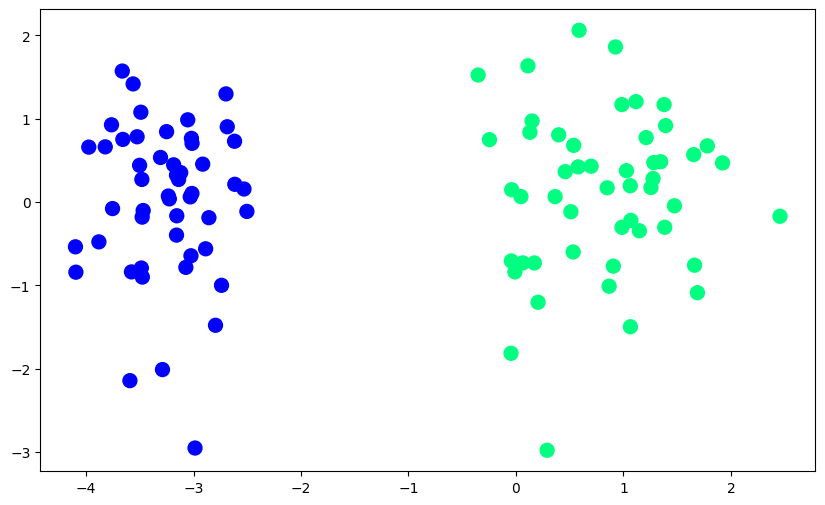

In [49]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter', s=100)

In [50]:
def perceptron(X,y):
  X = np.insert(X,0,1,axis=1)
  weights = np.ones(X.shape[1])
  lr = 0.1

  for i in range(1000):
    j = np.random.randint(0,100)
    y_hat = step(np.dot(X[j],weights))
    weights = weights + lr*(y[j]-y_hat)*X[j]

  return weights[0] , weights[1:]

In [51]:
def step(z):
  return 1 if z>0 else 0

In [52]:
intercept_,coef_ = perceptron(X,y)

In [53]:
print(coef_)
print(intercept_)

[1.0198596  0.33857969]
1.3000000000000003


In [54]:
X.shape

(100, 2)

In [55]:
np.dot(np.insert(X[41],0,1),[1,1,1])

np.float64(-1.40369174748523)

In [56]:
step(0.294)

1

In [57]:
step(-0.294)

0

In [58]:
m = -(coef_[0]/coef_[1])
c = -(intercept_/coef_[1])

In [59]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + c

(-3.0, 2.0)

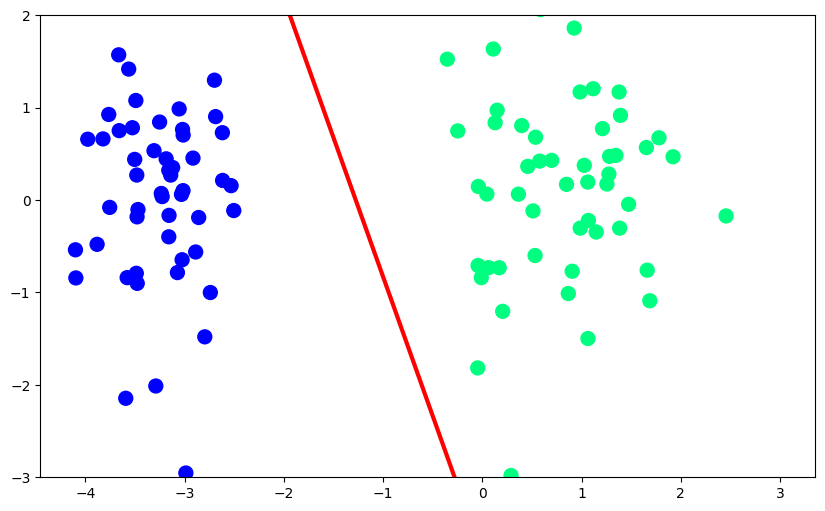

In [60]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red', linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y , cmap='winter',s=100)
plt.ylim(-3,2)

In [61]:
def perceptron(X,y):
  m = []
  b = []

  X = np.insert(X,0,1,axis=1)
  weights = np.ones(X.shape[1])
  lr = 0.1

  for i in range(200):
    j = np.random.randint(0,100)
    y_hat = step(np.dot(X[j],weights))
    weights = weights + lr*(y[j]-y_hat)*X[j]

    m.append(-(weights[1]/weights[2]))
    b.append(-(weights[0]/weights[2]))

  return m,b

In [62]:
m,b = perceptron(X,y)

In [63]:
%matplotlib inline
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

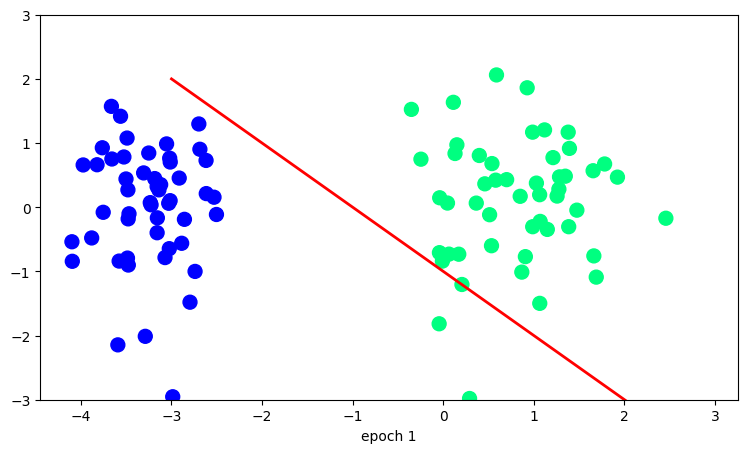

In [64]:
fig , ax = plt.subplots(figsize=(9,5))

x_i = np.arange(-3,3,0.1)
y_i = x_i*m[0] + b[0]
ax.scatter(X[:,0],X[:,1], c=y , cmap = 'winter', s=100)
line = ax.plot(x_i , x_i*m[0] + b[0] , 'r-' ,linewidth=2)
plt.ylim(-3,3)
def update(i):
  label = 'epoch {0}'.format(i+1)
  line[0].set_ydata(x_i*m[i] + b[i])
  ax.set_xlabel(label)

anim = FuncAnimation(fig,update,repeat=True,frames=200,interval=100)

In [65]:
from sklearn.linear_model import LogisticRegression
lor = LogisticRegression()
lor.fit(X,y)

LogisticRegression()

In [66]:
m = -(lor.coef_[0][0]/lor.coef_[0][1])
b = -(lor.intercept_/lor.coef_[0][1])

In [67]:
x_input1 = np.linspace(-3,3,100)
y_input1 = m*x_input + b

(-3.0, 2.0)

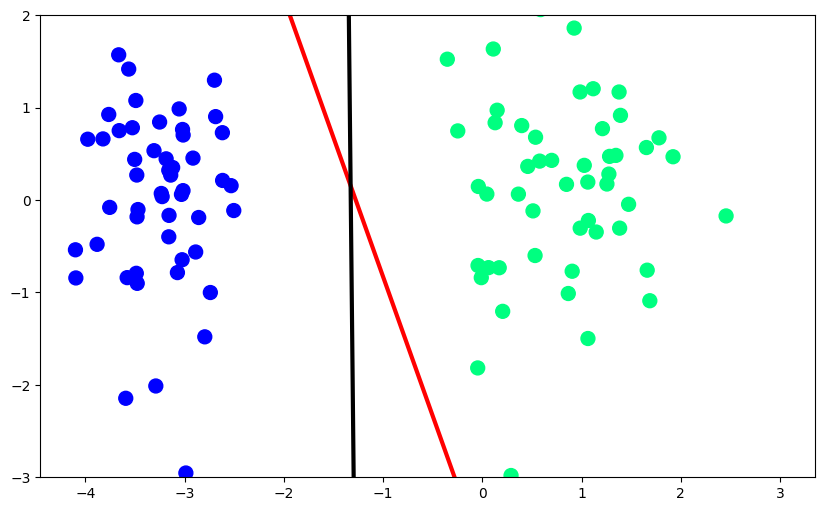

In [68]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red', linewidth=3)
plt.plot(x_input1 , y_input1 ,color='black' , linewidth = 3)
plt.scatter(X[:,0],X[:,1],c=y , cmap='winter',s=100)
plt.ylim(-3,2)